In [2]:
import os
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt

In [3]:
from common.configuration import DatasetPath, species_classes_map_all, species_by_familia, species_by_ordo
from common.stats import calculate_confusion_matrix, plot_confusion_matrix
from common.configuration import ModelPath, DatasetPath, species_invasive, species_native
from common.configuration import DatasetPath, ModelPath, species_native, species_label_map_all, species_classes_map_all

In [4]:
expert_estimation_excel_path = os.path.join(DatasetPath.real_historical_samples, "manual_analysis.xlsx")
expert_estimation_df = pd.read_excel(expert_estimation_excel_path, index_col=0).rename(columns={"Populus": "Populus tremula"}).fillna(0)
expert_estimation_df

,Corylus,Populus tremula,Alnus,Betula,Urtica,Salix,Acer,Ulmus,Pinus,Picea,Tilia,Plantago,Gramineae,Artemisia,Ambrosia,Chenopodiaceae,Apiaceae,Unknown,Rumex,Quercus
date,,,,,,,,,,,,,,,,,,,,
april 10,72,178,150,6,1,0,0,0,0,0,0,0,0,0,0,0,0,6,0,0.0
april 12,30,82,61,5,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,0.0
april 16,22,61,50,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0.0
april 18,57,149,166,13,0,4,0,0,0,0,0,0,0,0,0,1,0,6,0,0.0
may 1,0,0,1,447,10,749,228,0,1,18,1,0,0,1,0,1,0,0,0,0.0
may 21,0,0,19,16,10,0,27,0,0,0,0,0,0,1,2,5,0,0,0,0.0
june 10,0,0,1,7,29,2,5,4,2,0,0,247,27,1,0,1,0,0,0,0.0
june 17,0,0,0,0,19,0,0,5,0,0,0,340,4,5,0,3,0,0,0,0.0
june 25,10,0,1,11,42,0,0,2,0,0,0,82,19,7,0,4,0,0,0,0.0


In [5]:
def str_to_np(string):
    clean_string = string.strip('[]').replace('\n', ' ')
    array = np.fromstring(clean_string, sep=' ')
    return array

In [6]:
reference_prediction_path = "Save/reference_predictions.csv"
reference_prediction_df = pd.read_csv(reference_prediction_path, index_col=0).fillna(0)
reference_prediction_df.embeddings = reference_prediction_df.embeddings.map(str_to_np)
reference_prediction_df

,label,prediction,embeddings,image
0,Acer,Acer,"[4.396412, 0.2449137, -0.80762184, 2.0789647, ...",Dataset/pollen_dataset_2025_02_05\samples/Acer...
1,Acer,Acer,"[6.5362225, 1.0517198, -1.3801564, 1.075449, 1...",Dataset/pollen_dataset_2025_02_05\samples/Acer...
2,Acer,Acer,"[5.9718475, -0.38173628, -0.6895616, 0.7391565...",Dataset/pollen_dataset_2025_02_05\samples/Acer...
3,Acer,Acer,"[6.712505, 0.6844996, -1.435263, 1.0684086, 0....",Dataset/pollen_dataset_2025_02_05\samples/Acer...
4,Acer,Acer,"[7.573977, 0.03823689, -0.55947745, 0.83228517...",Dataset/pollen_dataset_2025_02_05\samples/Acer...
...,...,...,...,...
1430,Malus,Acer,"[4.698799, 2.4068203, -0.41649652, 0.1697608, ...",Dataset/pollen_dataset_2025_02_05\samples/Malu...
1431,Malus,Acer,"[5.3533034, 1.470593, 0.31046188, -1.6700553, ...",Dataset/pollen_dataset_2025_02_05\samples/Malu...
1432,Malus,Acer,"[4.9781733, 1.9623456, -0.5365845, -0.65549326...",Dataset/pollen_dataset_2025_02_05\samples/Malu...
1433,Malus,Acer,"[4.8460608, -1.0959177, -1.1885815, -0.3529814...",Dataset/pollen_dataset_2025_02_05\samples/Malu...


In [11]:
reference_prediction_df.label.unique()

array(['Acer', 'Alnus', 'Apiaceae', 'Artemisia', 'Betula',
       'Chenopodiaceae', 'Corylus', 'Picea', 'Pinus', 'Plantago',
       'Poaceae', 'Populus tremula', 'Quercus', 'Rumex', 'Salix', 'Tilia',
       'Urtica', 'Ulmus', 'Ambrosia', 'Taraxacum', 'Malus'], dtype=object)

In [17]:
embeddings_prediction_df = reference_prediction_df.copy()


for pred in reference_prediction_df.prediction.unique():
    val = species_classes_map_all[pred]
    if val < 0 : continue
    embeddings_prediction_df[pred] = np.stack(reference_prediction_df.embeddings.to_numpy())[:, val]
    
embeddings_prediction_df = embeddings_prediction_df.drop(columns=['embeddings']) 
embeddings_prediction_df.to_csv('embeddings.csv')
# embeddings_prediction_df



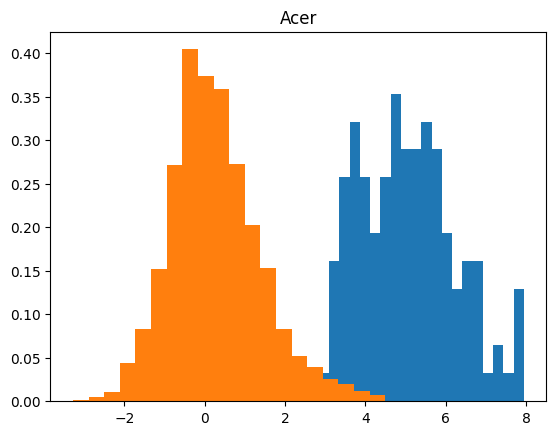

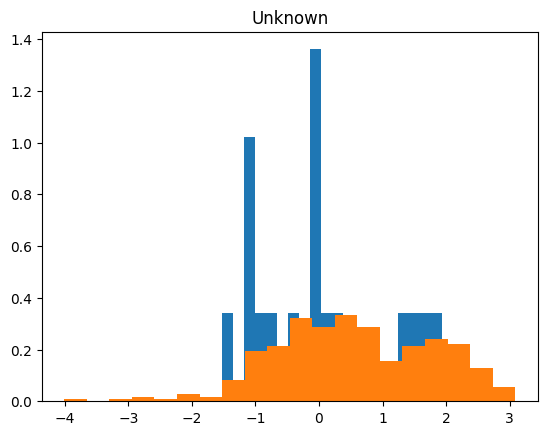

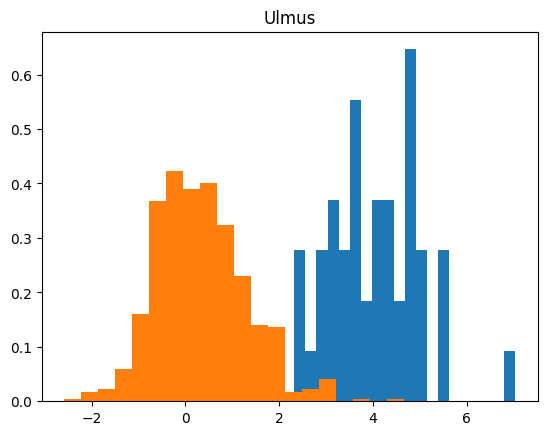

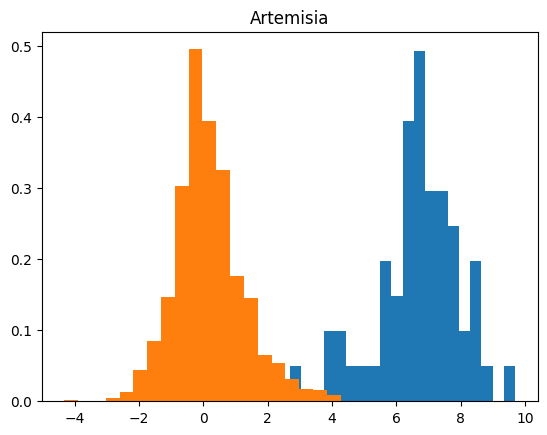

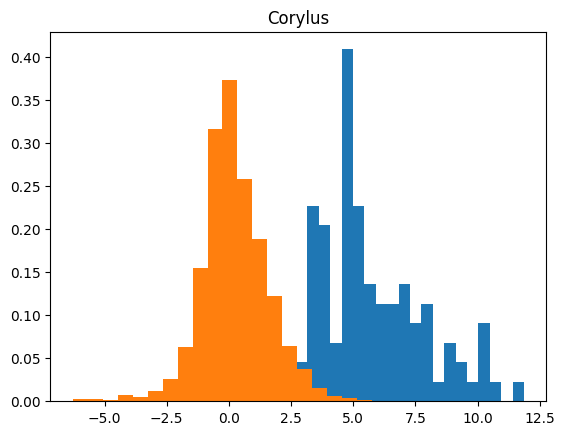

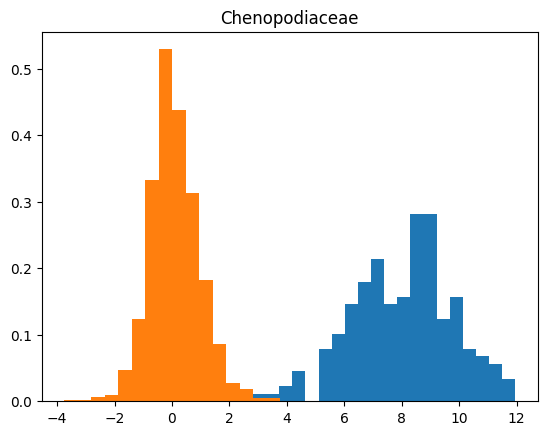

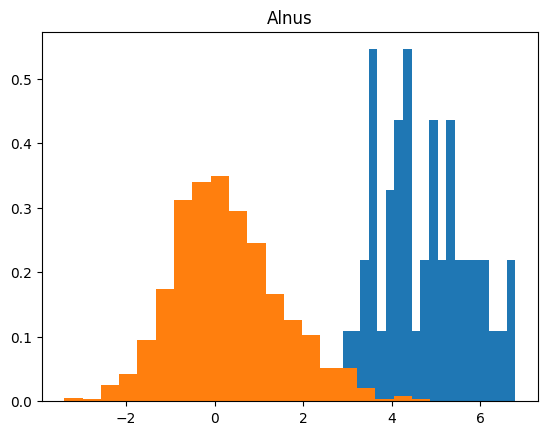

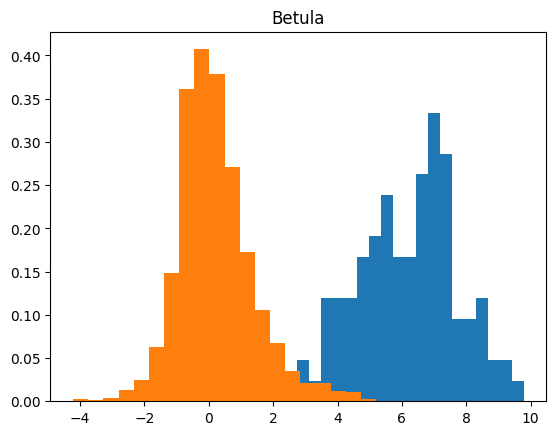

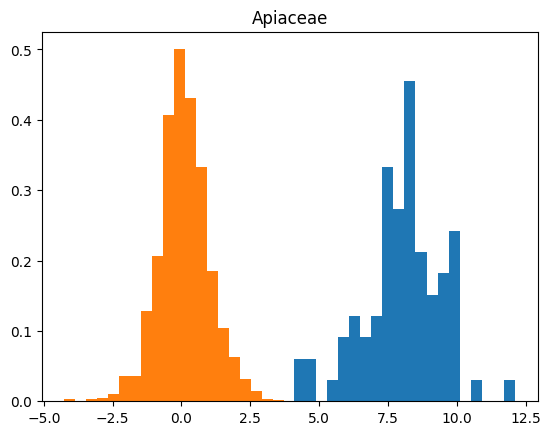

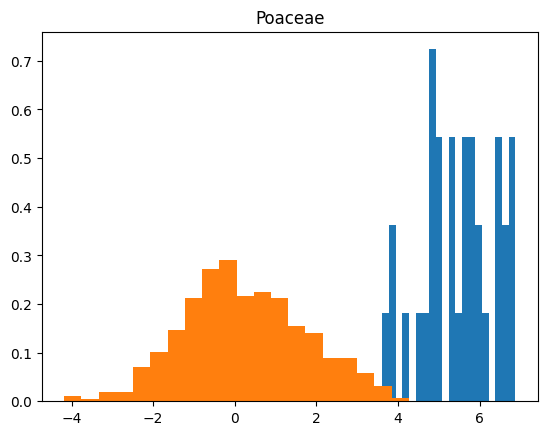

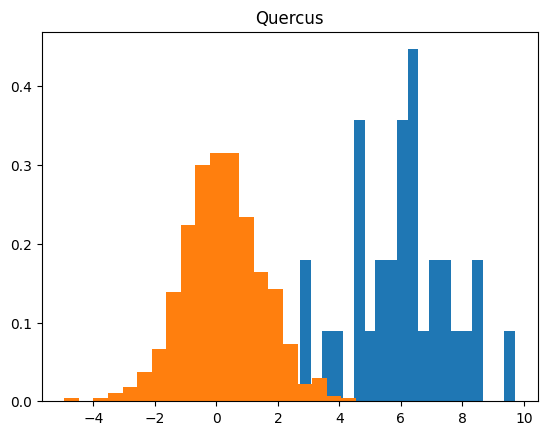

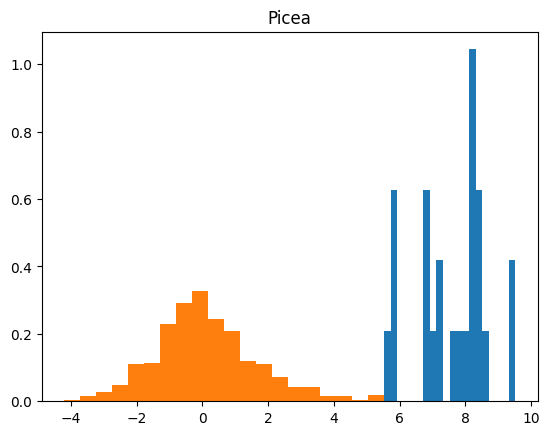

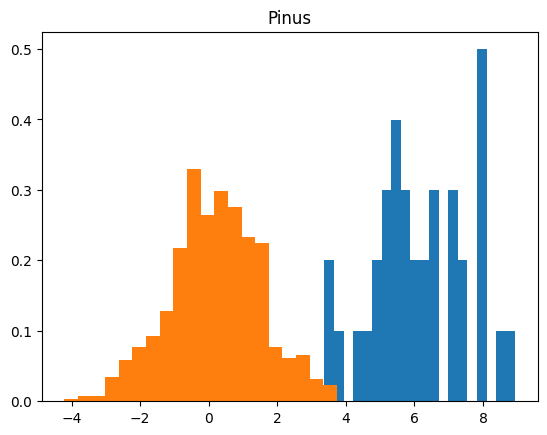

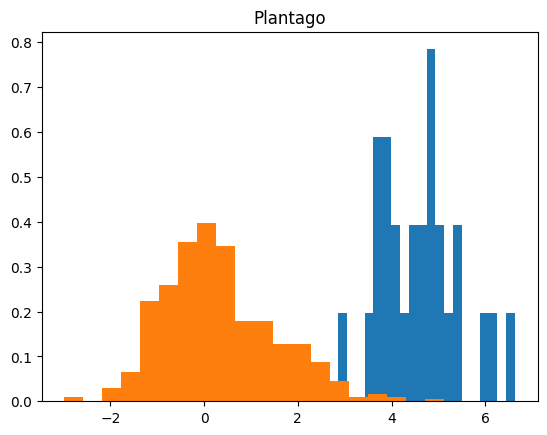

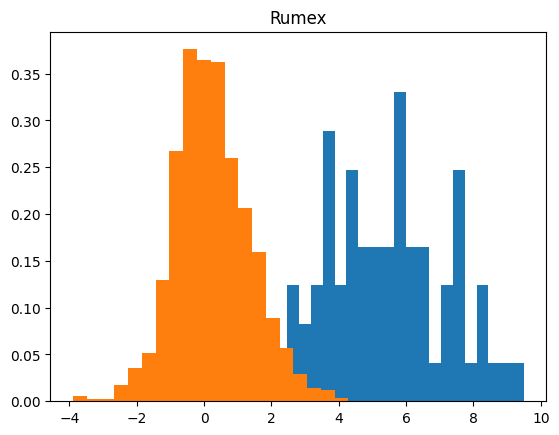

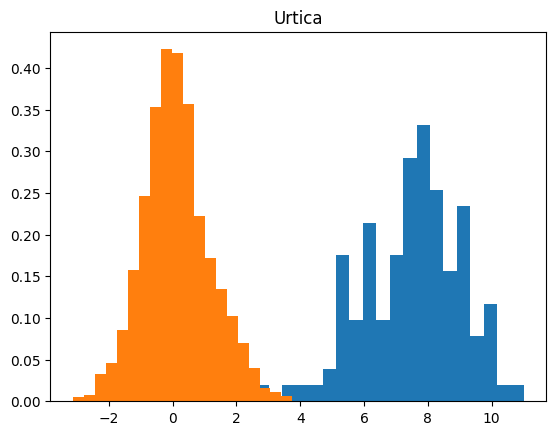

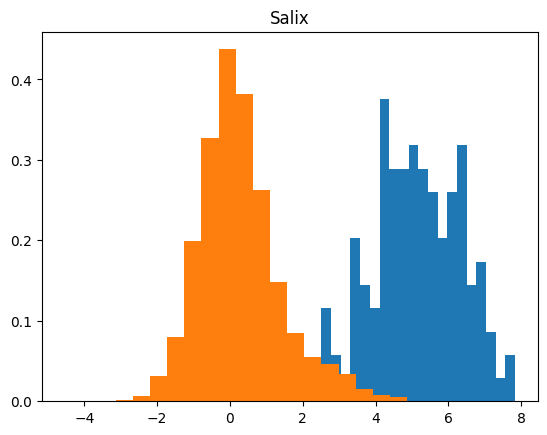

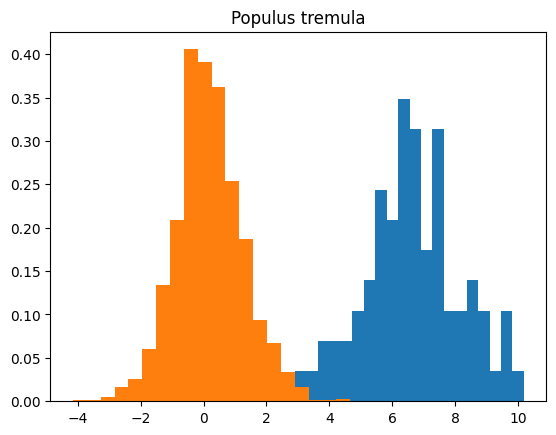

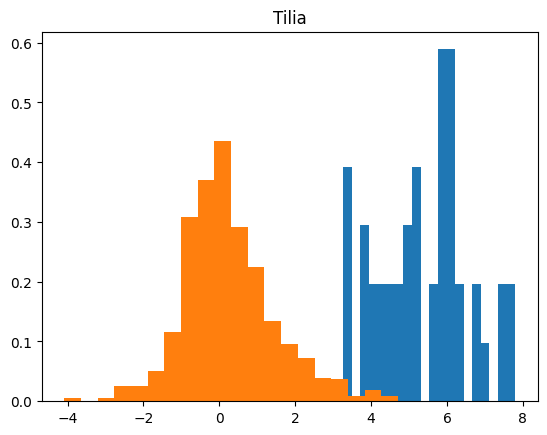

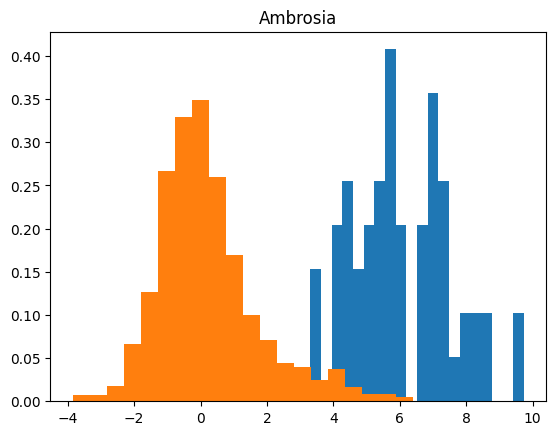

In [149]:
for pred in reference_prediction_df.prediction.unique():
    plt.figure()
    val = species_classes_map_all[pred]
    subset = reference_prediction_df[reference_prediction_df['prediction'] == pred]

    a = plt.hist(np.stack(subset.embeddings.to_numpy())[:, val].flatten(), bins=20, density=True)
    b = plt.hist(np.delete(np.stack(subset.embeddings.to_numpy()), val, axis=1).flatten(), bins=20, density=True)
    plt.title(pred)
    plt.plot()
# plt.ylim(0, 10)

In [163]:
from sklearn.metrics.pairwise import cosine_similarity

array([[0.7864446 ],
       [0.71775827],
       [0.81019502],
       [0.84906073],
       [0.81158685],
       [0.6195591 ],
       [0.77812825],
       [0.77263918],
       [0.49763502],
       [0.76236545],
       [0.68716418],
       [0.76300636],
       [0.77764447],
       [0.79938085],
       [0.79040272],
       [0.69905856],
       [0.8625624 ],
       [0.7214078 ],
       [0.75666651],
       [0.83084685],
       [0.73578477],
       [0.74514033],
       [0.57054421],
       [0.61779075],
       [0.69007651],
       [0.53195523],
       [0.69227625],
       [0.64979612],
       [0.62974646],
       [0.54033271],
       [0.63168534],
       [0.725199  ],
       [0.50973217],
       [0.7593122 ],
       [0.62831966],
       [0.68580656],
       [0.75537451],
       [0.67661994],
       [0.69240116],
       [0.70051326],
       [0.69626788],
       [0.65477981],
       [0.63740286],
       [0.66818371],
       [0.62411819],
       [0.52690947],
       [0.64501935],
       [0.507

In [182]:
anchors = np.zeros((np.stack(subset.embeddings.to_numpy()).shape[1], np.stack(subset.embeddings.to_numpy()).shape[1]))
np.fill_diagonal(anchors, 10)

In [193]:
anchors = np.zeros((19, 19))
np.fill_diagonal(anchors, 10)
print(anchors)

[[10.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.]
 [ 0. 10.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.]
 [ 0.  0. 10.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.]
 [ 0.  0.  0. 10.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.]
 [ 0.  0.  0.  0. 10.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.]
 [ 0.  0.  0.  0.  0. 10.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.]
 [ 0.  0.  0.  0.  0.  0. 10.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.]
 [ 0.  0.  0.  0.  0.  0.  0. 10.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0. 10.  0.  0.  0.  0.  0.  0.  0.  0.  0.
   0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0. 10.  0.  0.  0.  0.  0.  0.  0.  0.
   0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0. 10.  0.  0.  0.  0.  0.  0.  0.
   0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0. 10.  0.  0.  0.  0.  0.  0.
   0.]
 [ 0.  0.  0.  0.  0.  0.  0

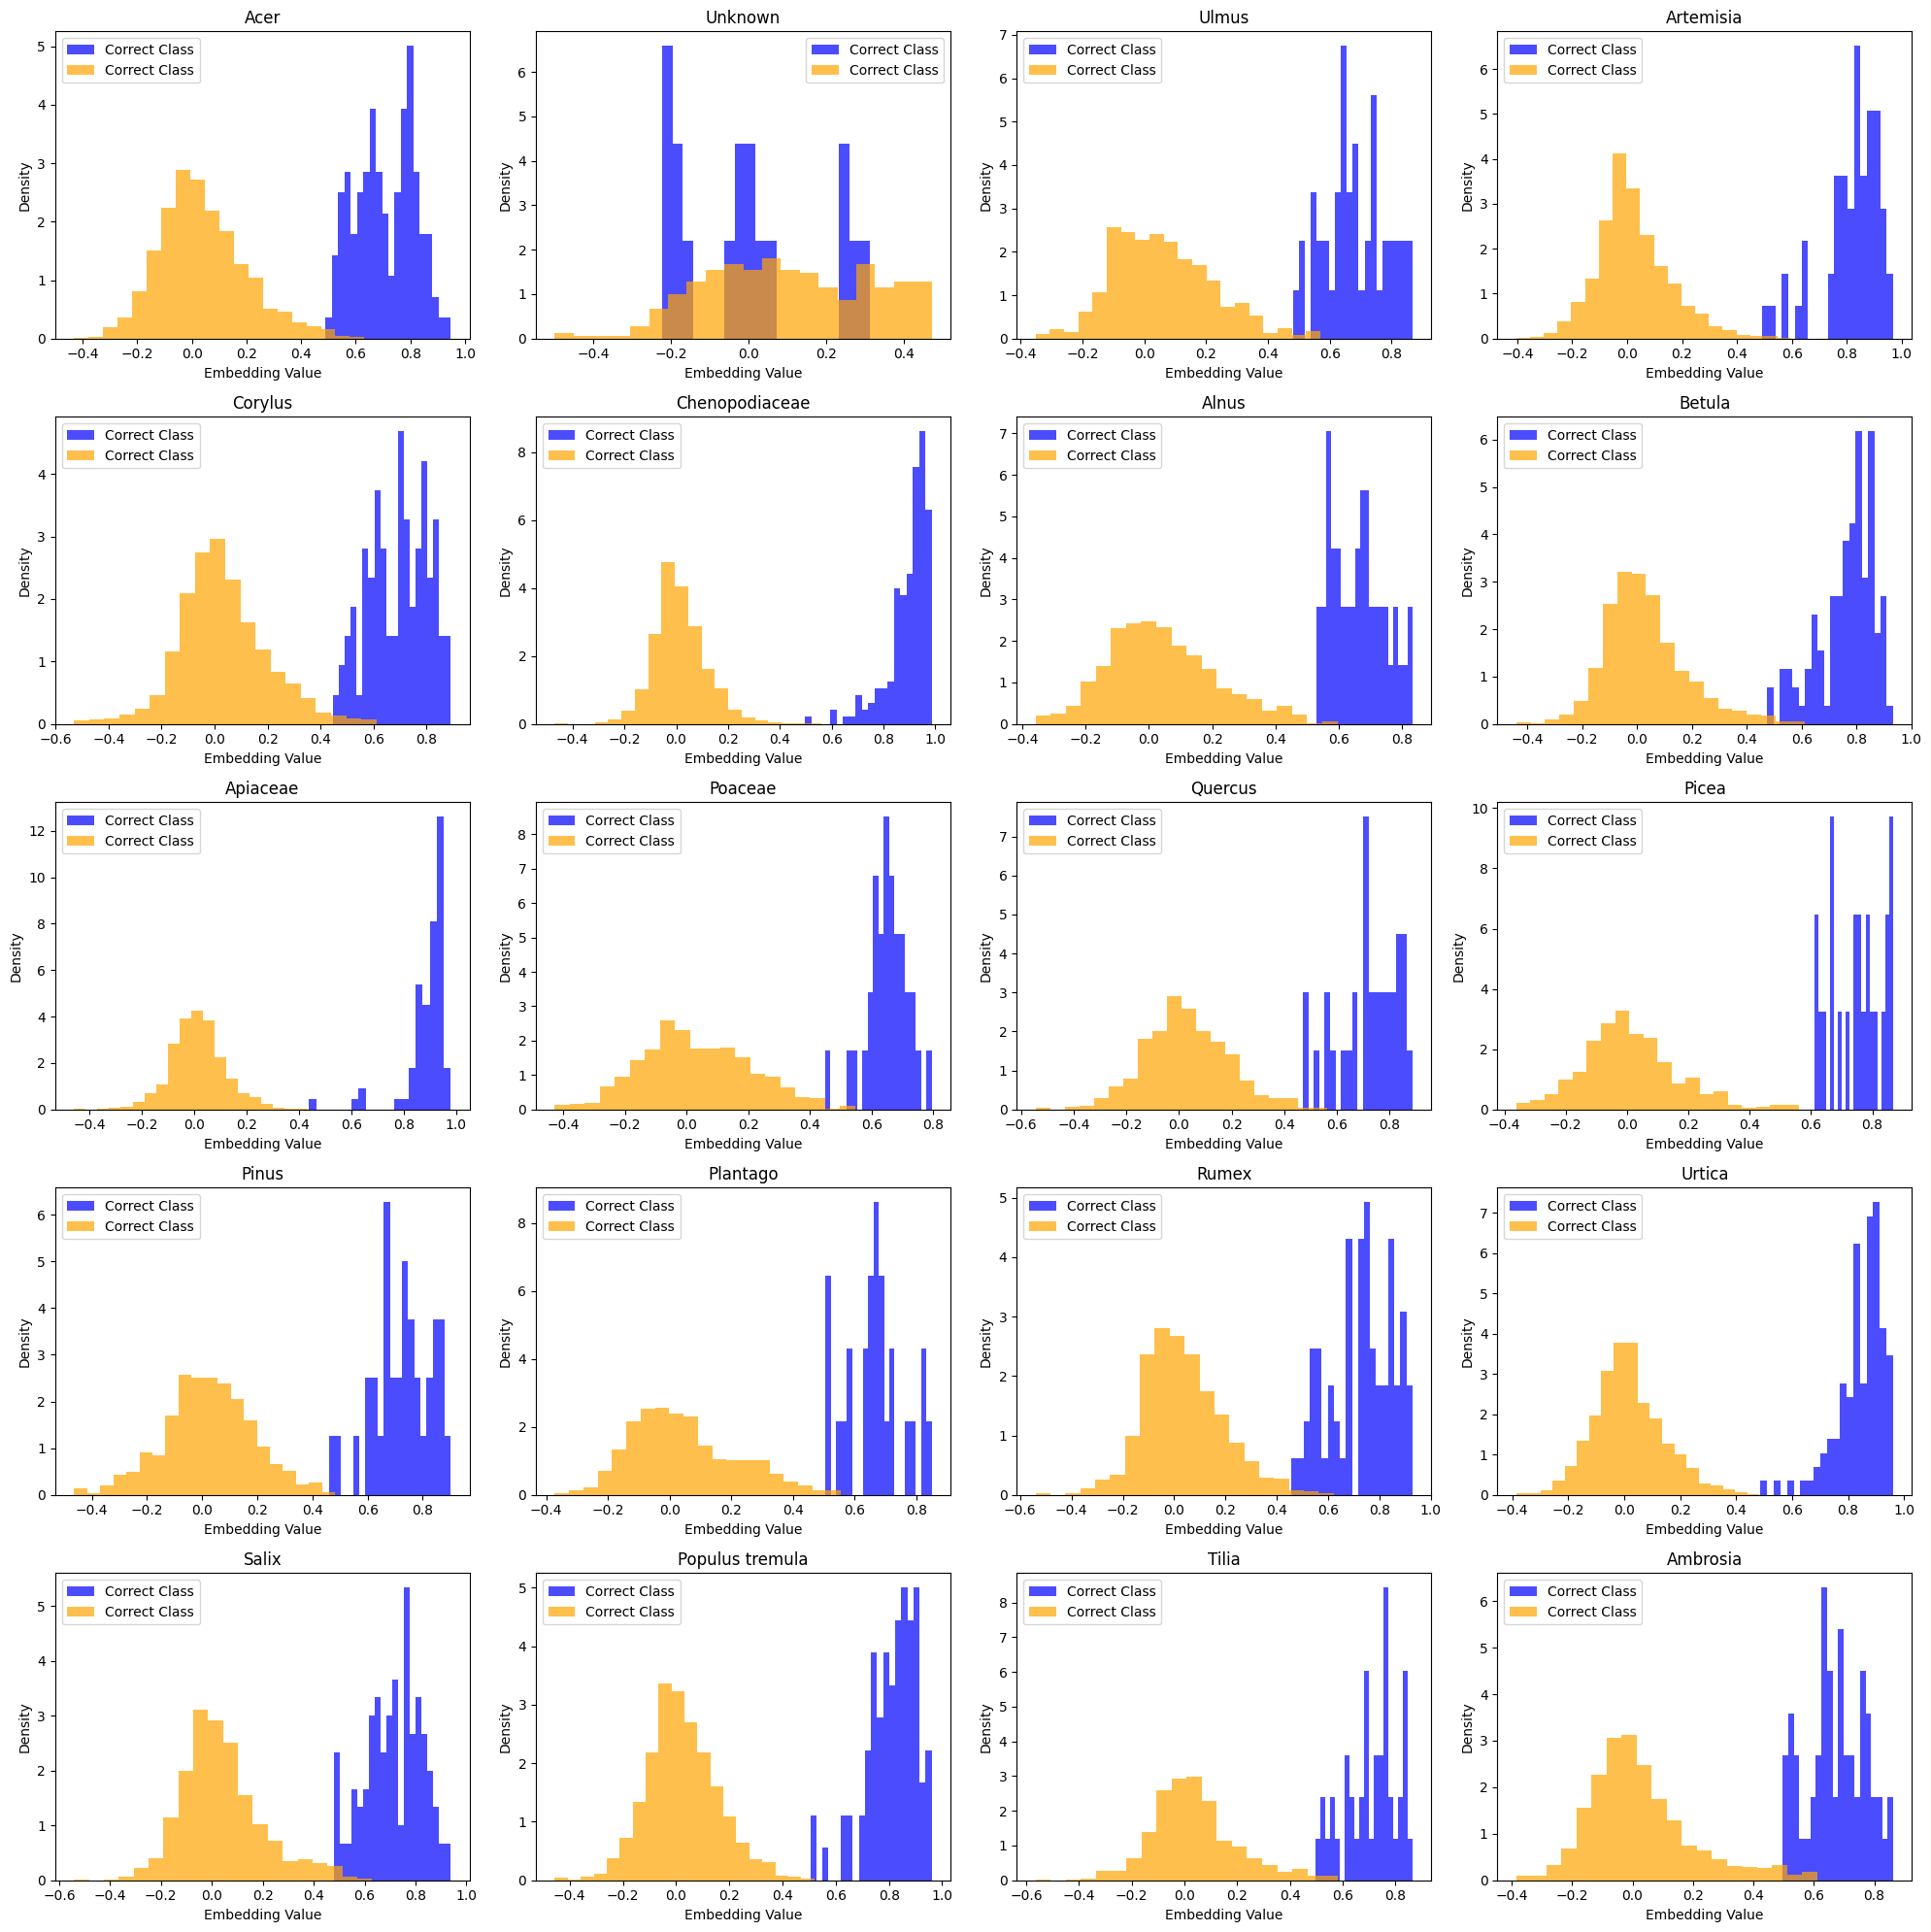

In [ ]:
unique_predictions = reference_prediction_df.prediction.unique()
n_preds = len(unique_predictions)

# Calculate grid dimensions
n_cols = 4  # Adjust based on preference
n_rows = int(np.ceil(n_preds / n_cols))

# Create figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))

# Handle case when there's only one subplot
if n_preds == 1:
    axes = [axes]
else:
    axes = axes.flatten()


anchors = np.zeros((19, 19))
np.fill_diagonal(anchors, 10)
for idx, pred in enumerate(unique_predictions):
    ax = axes[idx]
    val = species_classes_map_all[pred]
    subset = reference_prediction_df[reference_prediction_df['prediction'] == pred]
    
    anchor = anchors[val]

    # Plot histogram for correct class
    ax.hist(cosine_similarity(np.stack(subset.embeddings.to_numpy()), anchor.reshape(1, -1)), 
            bins=20, density=True, alpha=0.7, label='Correct Class', color='blue')
    
    # Plot histogram for other classes
    ax.hist(cosine_similarity(np.stack(subset.embeddings.to_numpy()), np.delete(anchors, val, axis=1).T).flatten(), 
            bins=20, density=True, alpha=0.7, label='Other Classes', color='orange')
    
    ax.set_title(pred)
    ax.legend()
    ax.set_xlabel('Embedding Value')
    ax.set_ylabel('Density')

# Remove empty subplots
for idx in range(n_preds, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

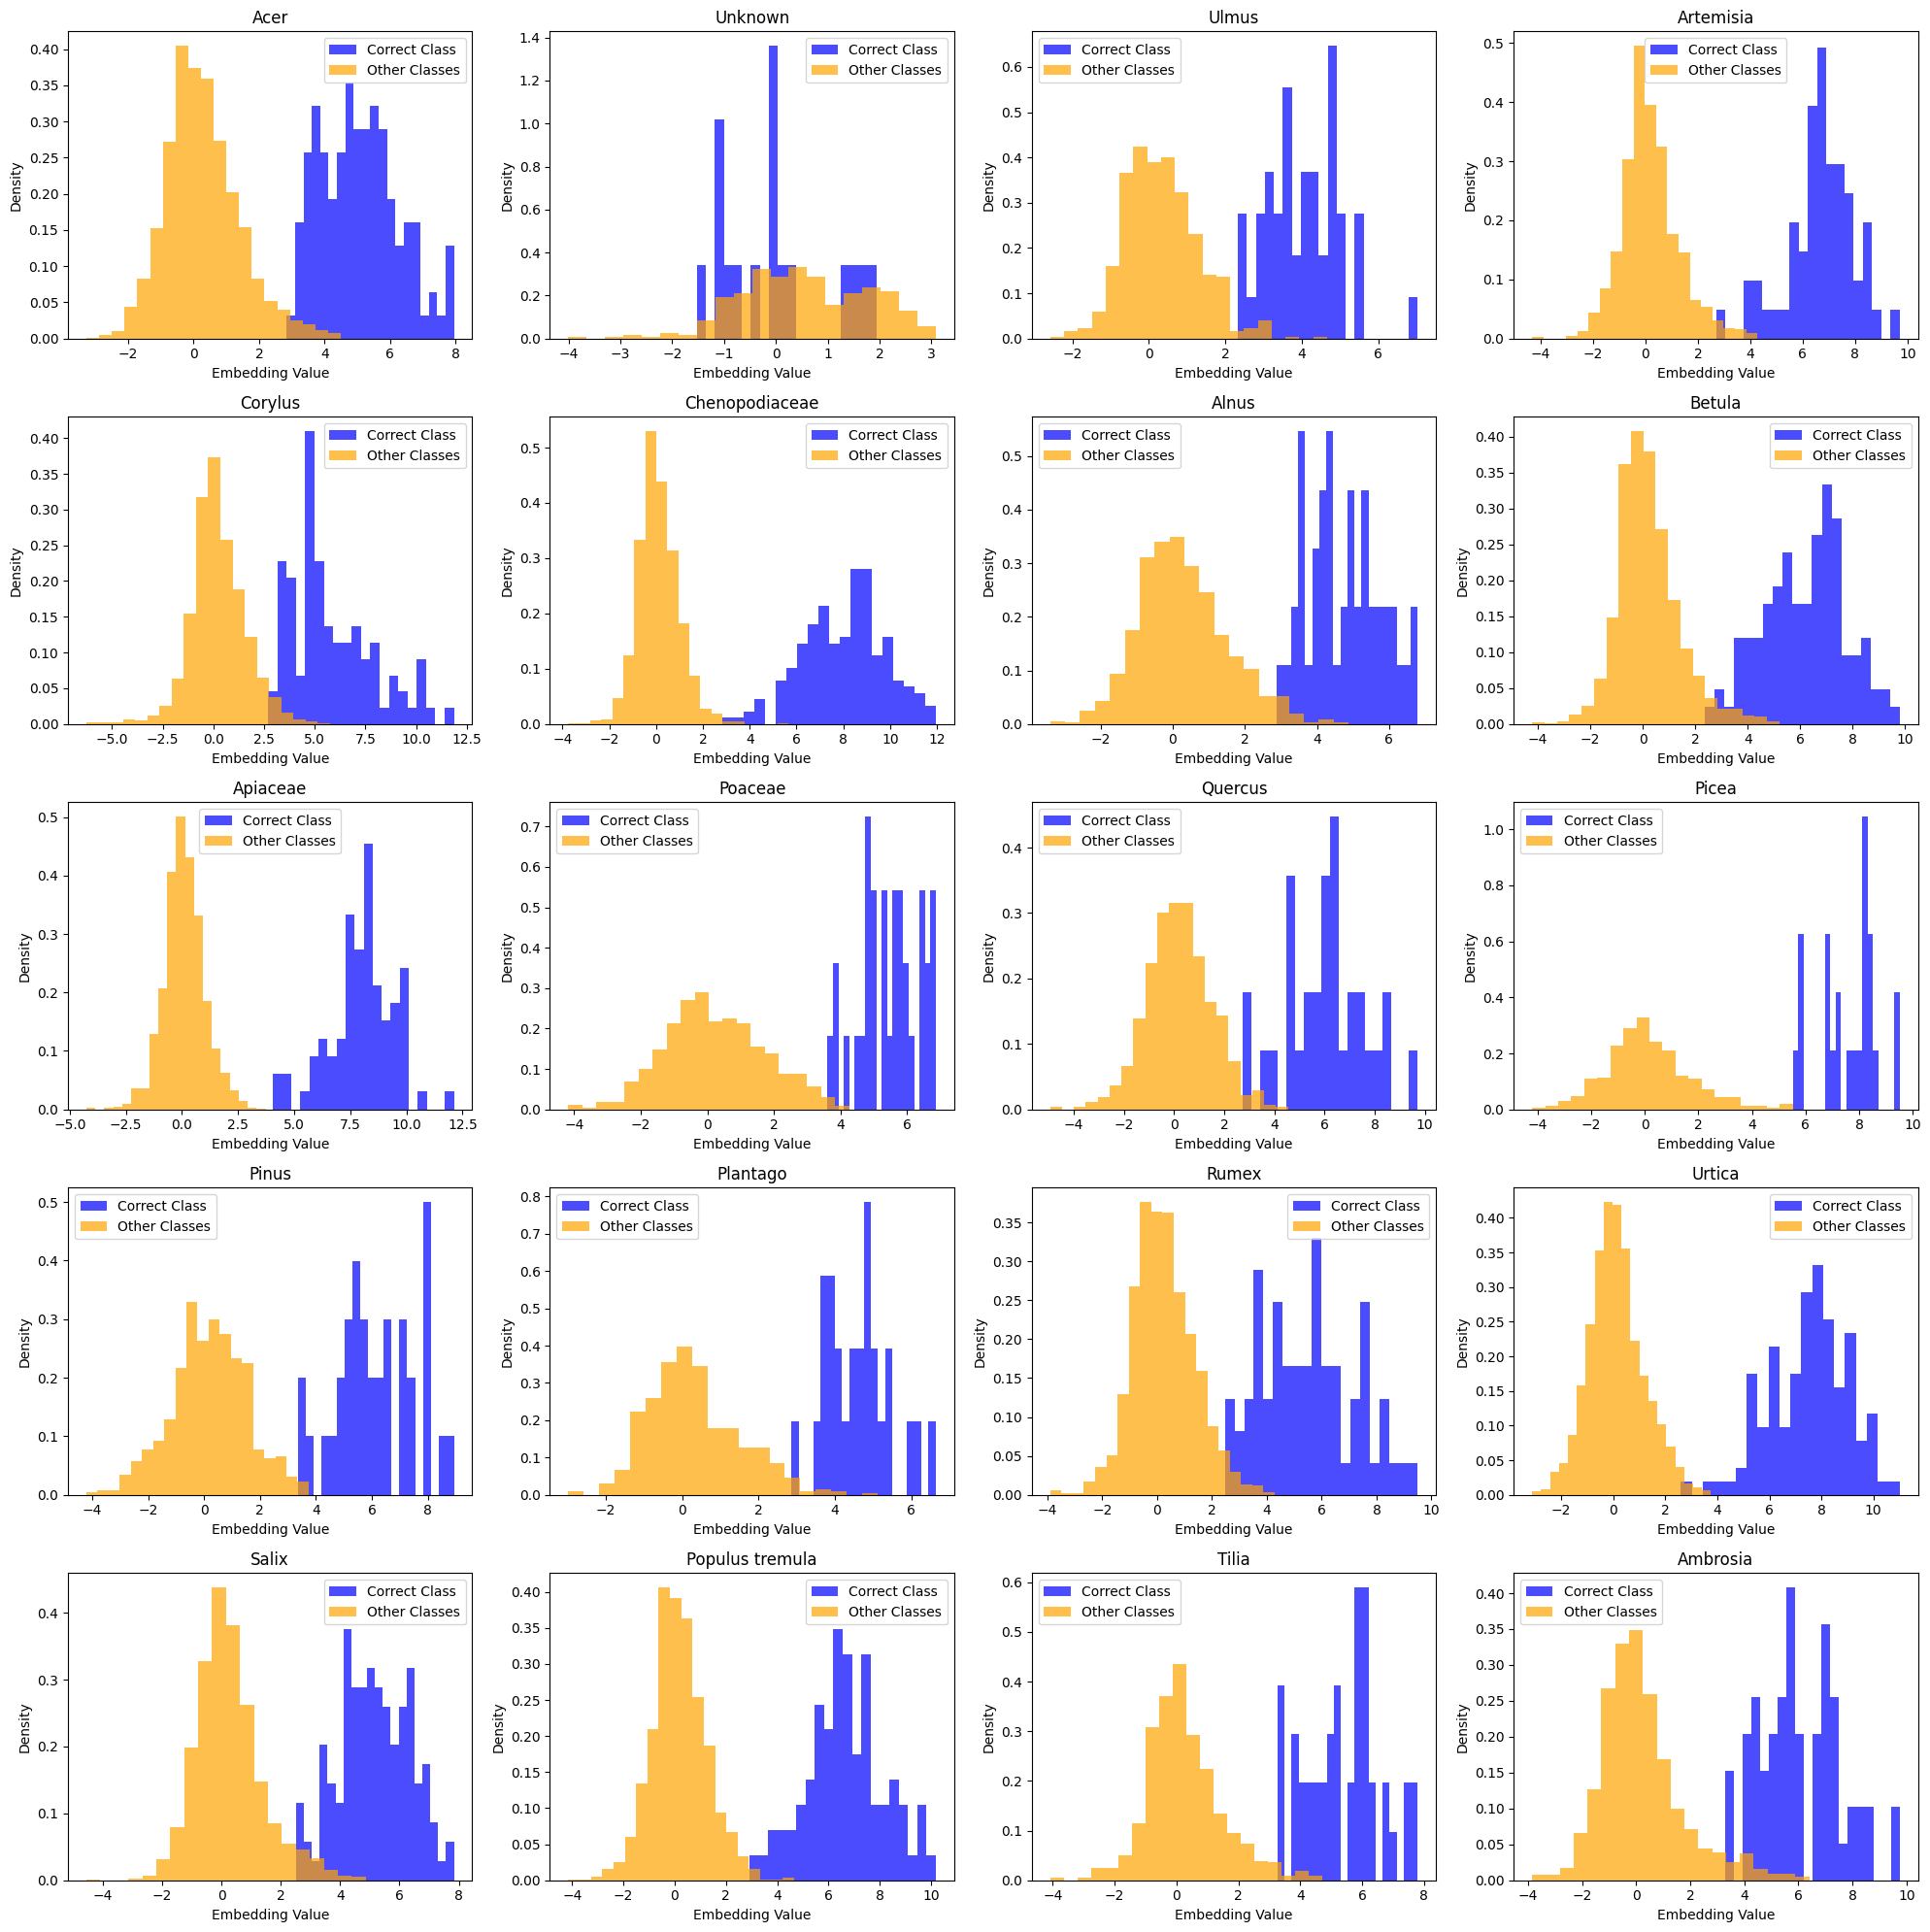

In [150]:
unique_predictions = reference_prediction_df.prediction.unique()
n_preds = len(unique_predictions)

# Calculate grid dimensions
n_cols = 4  # Adjust based on preference
n_rows = int(np.ceil(n_preds / n_cols))

# Create figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))

# Handle case when there's only one subplot
if n_preds == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for idx, pred in enumerate(unique_predictions):
    ax = axes[idx]
    val = species_classes_map_all[pred]
    subset = reference_prediction_df[reference_prediction_df['prediction'] == pred]
    
    # Plot histogram for correct class
    ax.hist(np.stack(subset.embeddings.to_numpy())[:, val].flatten(), 
            bins=20, density=True, alpha=0.7, label='Correct Class', color='blue')
    
    # Plot histogram for other classes
    ax.hist(np.delete(np.stack(subset.embeddings.to_numpy()), val, axis=1).flatten(), 
            bins=20, density=True, alpha=0.7, label='Other Classes', color='orange')
    
    ax.set_title(pred)
    ax.legend()
    ax.set_xlabel('Embedding Value')
    ax.set_ylabel('Density')

# Remove empty subplots
for idx in range(n_preds, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

In [ ]:
model_prediction_path = "Save/historical_embeddings.csv"
model_prediction_df = pd.read_csv(model_prediction_path, index_col=0).fillna(0)
model_prediction_df.embeddings = model_prediction_df.embeddings.map(str_to_np)
model_prediction_df

,subset,image,pollen_n,embeddings
0,april 10,Dataset/pollen_dataset_2025_02_05\historical_s...,0,[ 0.13830794 -0.0068111 0.76747125 0.112552...
1,april 10,Dataset/pollen_dataset_2025_02_05\historical_s...,0,[ 1.03169516e-01 -2.50267953e-01 7.86398202e-...
2,april 10,Dataset/pollen_dataset_2025_02_05\historical_s...,0,[ 0.4970327 0.9017924 -0.29776442 -0.178016...
3,april 10,Dataset/pollen_dataset_2025_02_05\historical_s...,1,[ 0.1183718 -0.18785995 -0.24735677 0.229967...
4,april 10,Dataset/pollen_dataset_2025_02_05\historical_s...,2,[ 0.63731 0.3864198 -0.23179846 0.158209...
...,...,...,...,...
5701,september 2,Dataset/pollen_dataset_2025_02_05\historical_s...,0,[-0.3961692 -0.12322986 0.519343 -0.313506...
5702,september 2,Dataset/pollen_dataset_2025_02_05\historical_s...,0,[ 2.729344 3.2510824 -0.74881893 0.099018...
5703,september 2,Dataset/pollen_dataset_2025_02_05\historical_s...,0,[ 8.210966 0.21644658 -0.68143314 0.958488...
5704,september 2,Dataset/pollen_dataset_2025_02_05\historical_s...,1,[ 5.8746986 -0.22889802 0.48396987 0.249685...


In [79]:
model_class_to_c_number_remap = {}
for i, c in enumerate(species_native):
    model_class_to_c_number_remap[i] = species_classes_map_all[c]

def prediction_to_class_name(prediction):
    predicted_c_number = model_class_to_c_number_remap.get(prediction, -1)
    return species_label_map_all[predicted_c_number]

In [84]:
prediction_to_class_name(11)

'Populus tremula'

(0.0, 100.0)

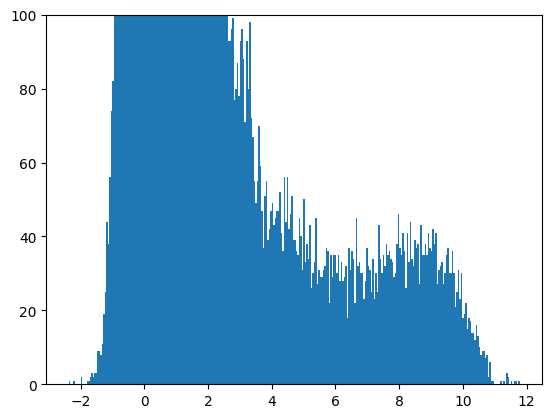

In [120]:
plt.hist(np.stack(model_prediction_df.embeddings.to_numpy()).flatten(), bins=300)
plt.ylim(0, 100)

In [ ]:
for date in expert_estimation_df.index:
    print("*"*20)
    print(date)
    images = list(filter(lambda x: date in x, model_prediction_df.image.unique()))

    subset = model_prediction_df[model_prediction_df['image'].isin(images)]
    subset_embeddings = np.stack(subset.embeddings.to_numpy())

    predictions = subset_embeddings.argmax(axis=1)

    threshold = 0.4

    cossims = cosine_similarity(subset_embeddings, anchors)
    
    print("By Genius")
    predicted = {}
    expected = {}
    for class_id in range(19):
        class_name = prediction_to_class_name(class_id)
        if class_name in expert_estimation_df.columns:
            expected[class_name] = expert_estimation_df.loc[date][class_name]
        else:
            expected[class_name] = 0

        predicted[class_name] = np.sum(cossims[:, class_id].flatten() > threshold)
        print(f"{class_name}... Expected: {expected[class_name]}, got: { predicted[class_name]}")
    
    print("By Ordo")

    predictions_ordo = {k: 0 for k in species_by_ordo.keys()}
    expected_ordo = {k: 0 for k in species_by_ordo.keys()}
    for ordo_name in species_by_ordo.keys():
        for class_name, predict in predicted.items():
            if class_name in species_by_ordo[ordo_name]:
                predictions_ordo[ordo_name] += predict
        for class_name, expect in expected.items():
            if class_name in species_by_ordo[ordo_name]:
                expected_ordo[ordo_name] += expect

    for ordo_name in species_by_ordo.keys():
        print(f"{ordo_name}... Expected: {expected_ordo[ordo_name]}, got: { predictions_ordo[ordo_name]}")
    break

april 10
By Genius
Acer... Expected: 0.0, got: 19
Alnus... Expected: 150.0, got: 18
Apiaceae... Expected: 0.0, got: 1
Artemisia... Expected: 0.0, got: 11
Betula... Expected: 6.0, got: 206
Chenopodiaceae... Expected: 0.0, got: 6
Corylus... Expected: 72.0, got: 8
Picea... Expected: 0.0, got: 4
Pinus... Expected: 0.0, got: 11
Plantago... Expected: 0.0, got: 0
Poaceae... Expected: 0, got: 15
Populus tremula... Expected: 178.0, got: 177
Quercus... Expected: 0.0, got: 4
Rumex... Expected: 0.0, got: 4
Salix... Expected: 0.0, got: 1
Tilia... Expected: 0.0, got: 3
Urtica... Expected: 1.0, got: 0
Ulmus... Expected: 0.0, got: 8
Ambrosia... Expected: 0.0, got: 11
By Ordo
Sapindales... Expected: 0.0, got: 19
Fagales... Expected: 228.0, got: 236
Rosales... Expected: 1.0, got: 8
Malpighiales... Expected: 178.0, got: 178
Malvales... Expected: 0.0, got: 3
Pinales... Expected: 0.0, got: 15
Apiales... Expected: 0.0, got: 1
Asterales... Expected: 0.0, got: 22
Poales... Expected: 0, got: 15
Caryophyllales.

In [210]:
predicted

11